In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.pipeline import FeatureUnion
from sklearn.svm import SVC, LinearSVC

RANDOM_STATE = 42

## Data Ingestion and Cleaning

In [2]:
df = pd.read_csv('sarcasm_cleanedV3.csv')

df.head()

,is_sarcastic,headline,article_link,word_count,cleaned_headline
0,1,thirtysomething scientists unveil doomsday clo...,https://www.theonion.com/thirtysomething-scien...,8,thirtysomething scientists unveil doomsday clo...
1,0,dem rep. totally nails why congress is falling...,https://www.huffingtonpost.com/entry/donna-edw...,13,dem rep totally nails why congress is falling ...
2,0,eat your veggies: 9 deliciously different recipes,https://www.huffingtonpost.com/entry/eat-your-...,7,eat your veggies 9 deliciously different recipes
3,1,inclement weather prevents liar from getting t...,https://local.theonion.com/inclement-weather-p...,8,inclement weather prevents liar from getting t...
4,1,mother comes pretty close to using word 'strea...,https://www.theonion.com/mother-comes-pretty-c...,9,mother comes pretty close to using word stream...


In [3]:
print("Shape of the dataset:", df.shape)

Shape of the dataset: (28503, 5)


In [4]:
print("Number of missing values in each column:")
print(df.isnull().sum())

Number of missing values in each column:
is_sarcastic        0
headline            0
article_link        0
word_count          0
cleaned_headline    0
dtype: int64


In [5]:
# Dropping the only missing row
df = df.dropna()

print("Number of missing values after handling nulls:")
print(df.isnull().sum())

Number of missing values after handling nulls:
is_sarcastic        0
headline            0
article_link        0
word_count          0
cleaned_headline    0
dtype: int64


In [6]:
print("Number of duplicate rows in the dataset:", df.duplicated().sum())

Number of duplicate rows in the dataset: 0


## Straified splitting 70/15/15 

In [7]:
X = df['cleaned_headline']
y = df['is_sarcastic']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=RANDOM_STATE)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE)

print("Training set size:", X_train.shape[0])
print("Validation set size:", X_val.shape[0])
print("Test set size:", X_test.shape[0])
print("—" * 50)
print(f"Training set class distribution: {y_train.value_counts(normalize=True).map('{:.3f}'.format)}")
print(f"\nValidation set class distribution: {y_val.value_counts(normalize=True).map('{:.3f}'.format)}")
print(f"\nTest set class distribution: {y_test.value_counts(normalize=True).map('{:.3f}'.format)}")

Training set size: 19952
Validation set size: 4275
Test set size: 4276
——————————————————————————————————————————————————
Training set class distribution: is_sarcastic
0    0.525
1    0.475
Name: proportion, dtype: object

Validation set class distribution: is_sarcastic
0    0.524
1    0.476
Name: proportion, dtype: object

Test set class distribution: is_sarcastic
0    0.525
1    0.475
Name: proportion, dtype: object


## TF-IDF Vectorization

In [8]:
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
)

In [9]:
# Final TF-IDF vectorizer (max_features=150000, ngram_range=(1, 2))
word_vec = TfidfVectorizer(
    analyzer="word",
    ngram_range=(1, 3),
    min_df=2,
    sublinear_tf=True,
    token_pattern=r"(?u)\b\w+\b|[?!]",
)

char_vec = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 6),
    min_df=2,
    sublinear_tf=True,
    max_features=300000,
)

vectorizer = FeatureUnion([("word", word_vec), ("char", char_vec)])  # type: ignore
X_train_tfidf = vectorizer.fit_transform(X_train)
X_val_tfidf = vectorizer.transform(X_val)
X_test_tfidf = vectorizer.transform(X_test)

In [10]:
print(f"Vocabulary size: {len(vectorizer.get_feature_names_out())}")
print("ngram_range: (1,3) for word, (2, 6) for char\n")
print(f"Shape of the TF-IDF matrix for training set: {X_train_tfidf.shape}")
print(f"Shape of the TF-IDF matrix for validation set: {X_val_tfidf.shape}")
print(f"Shape of the TF-IDF matrix for test set: {X_test_tfidf.shape}") 

Vocabulary size: 273387
ngram_range: (1,3) for word, (2, 6) for char

Shape of the TF-IDF matrix for training set: (19952, 273387)
Shape of the TF-IDF matrix for validation set: (4275, 273387)
Shape of the TF-IDF matrix for test set: (4276, 273387)


## Logistic Regression Model

C=1: Train Accuracy=0.9578, Validation Accuracy=0.8704
C=2: Train Accuracy=0.9801, Validation Accuracy=0.8723
C=3: Train Accuracy=0.9895, Validation Accuracy=0.8716
C=5: Train Accuracy=0.9957, Validation Accuracy=0.8690
C=10: Train Accuracy=0.9996, Validation Accuracy=0.8716
C=100: Train Accuracy=1.0000, Validation Accuracy=0.8685
C=200: Train Accuracy=0.9996, Validation Accuracy=0.8625
C=300: Train Accuracy=0.9997, Validation Accuracy=0.8622
Max validation Accuracy: 0.8723 at C=2


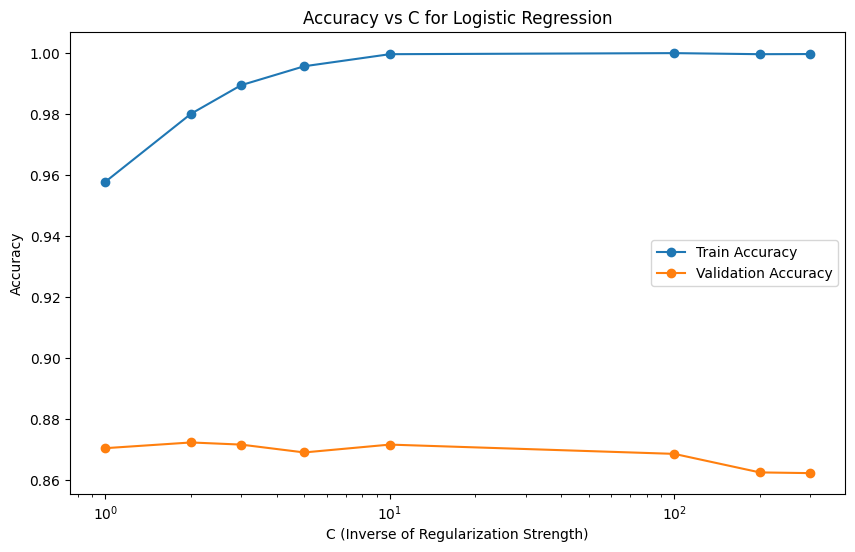

In [11]:
C_values = [1, 2, 3, 5, 10, 100, 200, 300]
train_acc_scores = []
val_acc_scores = []
for C in C_values:
    model = LogisticRegression(C=C, random_state=RANDOM_STATE, max_iter=10000)
    model.fit(X_train_tfidf, y_train)
    train_acc= accuracy_score(y_train, model.predict(X_train_tfidf))
    val_acc = accuracy_score(y_val, model.predict(X_val_tfidf))
    print(f"C={C}: Train Accuracy={train_acc:.4f}, Validation Accuracy={val_acc:.4f}")
    train_acc_scores.append(train_acc)
    val_acc_scores.append(val_acc)

best_c = C_values[val_acc_scores.index(max(val_acc_scores))]
print(f"Max validation Accuracy: {max(val_acc_scores):.4f} at C={best_c}")

plt.subplots(figsize=(10, 6))
plt.plot(C_values, train_acc_scores, marker='o', label='Train Accuracy')
plt.plot(C_values, val_acc_scores, marker='o', label='Validation Accuracy')
plt.xscale('log')
plt.xlabel('C (Inverse of Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs C for Logistic Regression')
plt.legend()
plt.show()

In [12]:
lr_model = LogisticRegression(C=best_c, random_state=RANDOM_STATE, max_iter=10000)
lr_model.fit(X_train_tfidf, y_train)

LogisticRegression(C=2, max_iter=10000, random_state=42)

## Linear SVM 

C=0.01: Train Accuracy=0.8781, Validation Accuracy=0.8456
C=0.05: Train Accuracy=0.9352, Validation Accuracy=0.8671
C=0.1: Train Accuracy=0.9620, Validation Accuracy=0.8720
C=1: Train Accuracy=0.9999, Validation Accuracy=0.8723
C=2: Train Accuracy=1.0000, Validation Accuracy=0.8704
C=5: Train Accuracy=1.0000, Validation Accuracy=0.8660
C=10: Train Accuracy=1.0000, Validation Accuracy=0.8653
Max validation Accuracy: 0.8723 at C=1


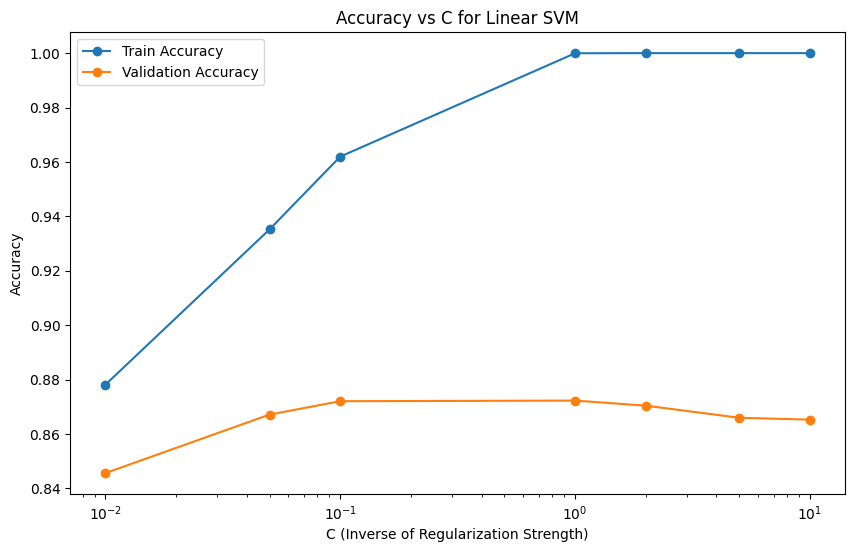

In [13]:
C_values = [0.01, 0.05, 0.1, 1, 2, 5, 10]
train_acc_scores = []
val_acc_scores = []
for c in C_values:
    model = LinearSVC(C=c, random_state=RANDOM_STATE, max_iter=10000)
    model.fit(X_train_tfidf, y_train)
    train_acc = accuracy_score(y_train, model.predict(X_train_tfidf))
    val_acc = accuracy_score(y_val, model.predict(X_val_tfidf))
    print(f"C={c}: Train Accuracy={train_acc:.4f}, Validation Accuracy={val_acc:.4f}")
    train_acc_scores.append(train_acc)
    val_acc_scores.append(val_acc)

best_c = C_values[val_acc_scores.index(max(val_acc_scores))]
print(f"Max validation Accuracy: {max(val_acc_scores):.4f} at C={C_values[val_acc_scores.index(max(val_acc_scores))]}")

plt.subplots(figsize=(10, 6))
plt.plot(C_values, train_acc_scores, marker='o', label='Train Accuracy')
plt.plot(C_values, val_acc_scores, marker='o', label='Validation Accuracy')
plt.xscale('log')
plt.xlabel('C (Inverse of Regularization Strength)')
plt.ylabel('Accuracy')
plt.title('Accuracy vs C for Linear SVM')
plt.legend()
plt.show()

In [14]:
svm_model = LinearSVC(C=best_c, random_state=RANDOM_STATE, max_iter=10000)
svm_model.fit(X_train_tfidf, y_train)

LinearSVC(C=1, max_iter=10000, random_state=42)

## Ensemble of LR and SVM (Bonus)

In [15]:
from sklearn.ensemble import StackingClassifier

estimators = [
    ('lr', lr_model),
    ('svm', svm_model)
]

meta_model = LogisticRegression(random_state=RANDOM_STATE)

stacking_model = StackingClassifier(estimators=estimators, final_estimator=meta_model, cv=5)

stacking_model.fit(X_train_tfidf, y_train)
y_pred = stacking_model.predict(X_val_tfidf)

print("Training F1 Score:", f1_score(y_train, stacking_model.predict(X_train_tfidf)))
print("Validation F1 Score:", f1_score(y_val, y_pred))

Training F1 Score: 0.9973105521278278
Validation F1 Score: 0.8661764705882353


## Test Evaluation of 3 models

In [16]:
models = {
    "Logistic Regression": lr_model,
    "Linear SVM": svm_model,
    "Stacking (LR + SVM)": stacking_model,
}

class_names = ["Not Sarcastic", "Sarcastic"]
summary = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test_tfidf)
    predictions[name] = y_pred
    summary.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (sarcastic)": precision_score(y_test, y_pred),
        "Recall (sarcastic)": recall_score(y_test, y_pred),
        "F1 (sarcastic)": f1_score(y_test, y_pred),
        "F1 (macro)": f1_score(y_test, y_pred, average="macro"),
    })

summary_df = pd.DataFrame(summary).set_index("Model").round(4)
summary_df



,Accuracy,Precision (sarcastic),Recall (sarcastic),F1 (sarcastic),F1 (macro)
Model,,,,,
Logistic Regression,0.8625,0.8540,0.8574,0.8557,0.8622
Linear SVM,0.8630,0.8517,0.8618,0.8567,0.8627
Stacking (LR + SVM),0.8665,0.8555,0.8652,0.8604,0.8662


In [17]:
for name, y_pred in predictions.items():
    print(f"\t\t{name}\n")
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
    print("—"*55)

		Logistic Regression

               precision    recall  f1-score   support

Not Sarcastic     0.8702    0.8671    0.8687      2243
    Sarcastic     0.8540    0.8574    0.8557      2033

     accuracy                         0.8625      4276
    macro avg     0.8621    0.8622    0.8622      4276
 weighted avg     0.8625    0.8625    0.8625      4276

———————————————————————————————————————————————————————
		Linear SVM

               precision    recall  f1-score   support

Not Sarcastic     0.8734    0.8640    0.8687      2243
    Sarcastic     0.8517    0.8618    0.8567      2033

     accuracy                         0.8630      4276
    macro avg     0.8625    0.8629    0.8627      4276
 weighted avg     0.8631    0.8630    0.8630      4276

———————————————————————————————————————————————————————
		Stacking (LR + SVM)

               precision    recall  f1-score   support

Not Sarcastic     0.8766    0.8676    0.8721      2243
    Sarcastic     0.8555    0.8652    0.8604      2

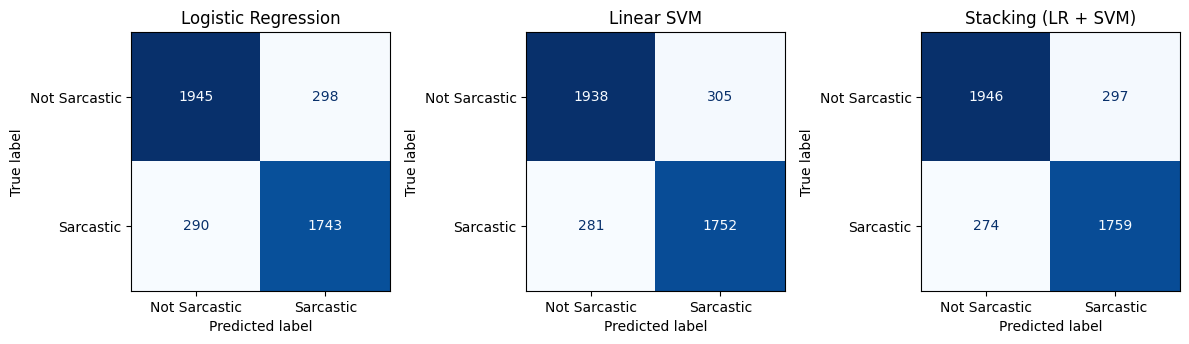

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

## Models Misclassification Analysis
- **Logistic Regression** and **Linear SVM** are pratically the same in numbers of correctly classified and missclassifed samples. The ensemble model is slightl better at **correctly classifying samples** (higher True Positives) and **lowering mistaking correct samples for incorrect ones** (lower False Positives) but it does worse at **correctly classifying incorrect samples** (lower True Negatives) and **mistaking incorrect samples for correct ones** (higher False Negatives).

In [19]:
# Top words affected that affect LR predictions
words = vectorizer.get_feature_names_out()
lr_coefs = lr_model.coef_[0]

coef_df = pd.DataFrame({
    "Word": words,
    "Coefficient": lr_coefs
})
# Words that strongly indicate Class 1 (Sarcastic)
print("Top 10 positive coefficients (Sarcastic):")
display(coef_df.sort_values(by="Coefficient", ascending=False).head(10))

# Words that strongly indicate Class 0 (Not Sarcastic)
print("\nTop 10 negative coefficients (Not Sarcastic):")
display(coef_df.sort_values(by="Coefficient", ascending=True).head(10))

Top 10 positive coefficients (Sarcastic):


,Word,Coefficient
20193,word__nation,5.990272
2878,word__area,5.875883
18585,word__man,5.563527
21364,word__of,4.201862
13405,word__he,3.706430
25753,word__report,3.526770
20430,word__new,3.043562
18070,word__local,3.012651
20207,word__nation s,2.977725
12917,word__guy,2.806123



Top 10 negative coefficients (Not Sarcastic):


,Word,Coefficient
30778,word__the,-10.297583
631,word__a,-7.522358
15936,word__is,-6.641009
2244,word__and,-6.433755
2178,word__an,-4.461965
2756,word__are,-4.436084
35973,word__why,-4.209174
14281,word__how,-3.716543
246782,char__the,-3.581768
37226,word__your,-3.320471


## Saving Vectorizer and Models

In [20]:
import joblib

joblib.dump(vectorizer, "../models/text/tfidf_vectorizer.pkl")
joblib.dump(lr_model, "../models/text/logistic_regression_model.pkl")
joblib.dump(svm_model, "../models/text/linear_svm_model.pkl")
joblib.dump(stacking_model, "../models/text/stacking_model.pkl")

['../models/text/stacking_model.pkl']